# 此代码用于构建个体级别的时空核密度

In [1]:
%matplotlib inline
import os
import pickle
from tqdm.auto import tqdm
from joblib import Parallel, delayed
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd
from shapely.geometry import Point, Polygon
from shapely import wkt
from sklearn.neighbors import KernelDensity
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from sklearn.cluster import KMeans, DBSCAN
from scipy.spatial.distance import cdist
from kneed import KneeLocator
from joblib import Parallel, delayed

In [2]:
# 设置中文字体
plt.rcParams['font.sans-serif'] = ['SimHei']

## data preprocessing

In [3]:
path = ['../../autodl-fs/region_slow_status_23q1.csv', '../../autodl-fs/region_slow_status_23q2_1.csv', 
        '../../autodl-fs/region_slow_status_23q2_2.csv', '../../autodl-fs/region_slow_status_23q3.csv',
        '../../autodl-fs/region_slow_status_24q1.csv', '../../autodl-fs/region_slow_status_24q2.csv',
        '../../autodl-fs/region_slow_status_24q3_1.csv', '../../autodl-fs/region_slow_status_24q3_2.csv']

In [4]:
# 创建空的DataFrame用于存储所有数据
full_data = pd.DataFrame()

# 循环读取所有文件并处理
for file_path in path:
    # 读取数据
    temp_data = pd.read_csv(file_path)
    
    # 重构数据
    temp_data['path_comlexity'] = temp_data['path_comlexity'] / 3.6 * 100
    temp_data['move_volatility'] = temp_data['move_volatility'] / 3.6 * 100 
    temp_data['active_fac'] = temp_data['active_fac'] * 1000

    # 重命名
    temp_data.rename(columns={'path_comlexity': 'lon', 
                            'move_volatility': 'lat',
                            'active_fac': 'pid'}, inplace=True)
    
    # 调整列顺序
    temp_data = temp_data[['pid', 'fnid', 'year', 'week_number', 'lon', 'lat', 'duration', 'frequency']]
    
    # 合并数据
    full_data = pd.concat([full_data, temp_data], ignore_index=True)

full_data.head()

,pid,fnid,year,week_number,lon,lat,duration,frequency
0,52594571.0,42693,2023,16,114.262808,22.712093,107724,5
1,52596396.0,17191,2023,15,113.884277,22.555618,11563,1
2,52597634.0,16530,2023,10,114.013138,22.550354,2435,1
3,52597794.0,45544,2023,16,114.250551,22.730485,73987,3
4,52606245.0,12966,2023,13,114.027512,22.528355,131045,4


In [5]:
# 按照pid, year, week_number排序
full_data = full_data.sort_values(['pid', 'year', 'week_number']).reset_index(drop=True)
full_data.head()

,pid,fnid,year,week_number,lon,lat,duration,frequency
0,263.0,38330,2023,9,114.070173,22.684969,105385,3
1,263.0,40463,2023,9,114.047149,22.699514,260035,9
2,263.0,40463,2023,10,114.047149,22.699514,352248,11
3,263.0,38330,2023,10,114.070173,22.684969,209070,5
4,263.0,44397,2023,10,114.066238,22.723160,2785,1


In [6]:
# 保存
full_data.to_csv('../data/stay_data_23_24.csv', index=False)

## 0. data load

In [2]:
full_data = pd.read_csv('../data/stay_data_23_24.csv')
full_data.head()

,pid,fnid,year,week_number,lon,lat,duration,frequency
0,263.0,38330,2023,9,114.070173,22.684969,105385,3
1,263.0,40463,2023,9,114.047149,22.699514,260035,9
2,263.0,40463,2023,10,114.047149,22.699514,352248,11
3,263.0,38330,2023,10,114.070173,22.684969,209070,5
4,263.0,44397,2023,10,114.066238,22.723160,2785,1


In [3]:
# 给full_data新增一列t
complete_time = full_data[['year', 'week_number']].drop_duplicates().sort_values(by=['year', 'week_number']).reset_index(drop=True)
complete_time['t'] = np.arange(len(complete_time))
full_data = full_data.merge(complete_time, on=['year', 'week_number'], how='left')
full_data.head()

,pid,fnid,year,week_number,lon,lat,duration,frequency,t
0,263.0,38330,2023,9,114.070173,22.684969,105385,3,0
1,263.0,40463,2023,9,114.047149,22.699514,260035,9,0
2,263.0,40463,2023,10,114.047149,22.699514,352248,11,1
3,263.0,38330,2023,10,114.070173,22.684969,209070,5,1
4,263.0,44397,2023,10,114.066238,22.723160,2785,1,1


In [4]:
print(len(full_data))
print(full_data['pid'].nunique())

114274415
197505


### 选择样本

1. 职住调整情况：仅迁居、仅更换工作地，或进行职住调整，但是两者间隔周数<=8weeks，视为耦合事件
2. 搬迁前至少有10周的数据-用于建立基线行为模式
3. 搬迁后至少有20周的数据-确认新均衡状态

In [4]:
# 导入迁居信息
outcome = pd.read_csv('../../autodl-fs/slow_dist_data.csv')
relocate_info = outcome[['pid', 'home_year', 'home_week', 'home_time', 'work_year', 'work_week', 'work_time']].drop_duplicates()
relocate_info.head()

,pid,home_year,home_week,home_time,work_year,work_week,work_time
0,263.0,2024.0,26.0,69.0,-1.0,-1.0,-1.0
87,270.0,2023.0,51.0,42.0,-1.0,-1.0,-1.0
174,712.0,2023.0,16.0,7.0,-1.0,-1.0,-1.0
261,2753.0,2024.0,12.0,55.0,-1.0,-1.0,-1.0
348,3203.0,2023.0,47.0,38.0,-1.0,-1.0,-1.0


In [5]:
# 预计算每个个体的最大时间
max_t_dict = full_data.groupby('pid')['t'].max().to_dict()

# 预处理步骤：为relocate_info添加max_t列
relocate_info['max_t'] = relocate_info['pid'].map(max_t_dict)

# 1. 仅迁居样本
mask_only_home = (relocate_info['home_time'] >= 0) & (relocate_info['work_time'] < 0)
mask_home_time = (relocate_info['home_time'] >= 9) & (relocate_info['max_t'] - relocate_info['home_time'] >= 20)
only_home = relocate_info[mask_only_home & mask_home_time].copy()

# 2. 仅更换工作样本
mask_only_work = (relocate_info['work_time'] >= 0) & (relocate_info['home_time'] < 0)
mask_work_time = (relocate_info['work_time'] >= 9) & (relocate_info['max_t'] - relocate_info['work_time'] >= 20)
only_work = relocate_info[mask_only_work & mask_work_time].copy()

# 3. 职住同时调整且间隔<=8周的样本
mask_both = (relocate_info['home_time'] >= 0) & (relocate_info['work_time'] >= 0)
both_change = relocate_info[mask_both].copy()
both_change['time_gap'] = (both_change['home_time'] - both_change['work_time']).abs()

# 合并时间条件筛选
mask_both_time = (
    (both_change['home_time'] >= 9) & 
    (both_change['max_t'] - both_change['home_time'] >= 20) &
    (both_change['work_time'] >= 9) & 
    (both_change['max_t'] - both_change['work_time'] >= 20) &
    (both_change['time_gap'] <= 8)
)
both_change = both_change[mask_both_time]

# 合并三类样本
relocate_info_filter = pd.concat([
    only_home[['pid', 'home_time', 'work_time', 'max_t']],
    only_work[['pid', 'home_time', 'work_time', 'max_t']],
    both_change[['pid', 'home_time', 'work_time', 'max_t']]
], ignore_index=True)

print(f"样本数量: {len(relocate_info_filter)}")
print(relocate_info_filter.head())

样本数量: 110261
      pid  home_time  work_time  max_t
0   270.0       42.0       -1.0     77
1  2753.0       55.0       -1.0     77
2  3203.0       38.0       -1.0     78
3  4100.0       11.0       -1.0     78
4  4658.0       52.0       -1.0     78


In [6]:
# 选取在outcome中的pid
full_data = full_data[full_data['pid'].isin(relocate_info_filter['pid'])]
print(full_data['pid'].nunique())

# 根据pid关联home_year, home_week, work_year, work_week四列
full_data = pd.merge(full_data, relocate_info_filter[['pid', 'home_time', 'work_time']], on='pid', how='left')

full_data.head()

110261


,pid,fnid,year,week_number,lon,lat,duration,frequency,t,home_time,work_time
0,270.0,35084,2023,9,113.990100,22.664861,285252,5,0,42.0,-1.0
1,270.0,16184,2023,10,114.040146,22.548752,5816,1,1,42.0,-1.0
2,270.0,35084,2023,10,113.990100,22.664861,299368,8,1,42.0,-1.0
3,270.0,35444,2023,10,113.997586,22.666864,20705,2,1,42.0,-1.0
4,270.0,35084,2023,11,113.990100,22.664861,266073,6,2,42.0,-1.0


<Axes: >

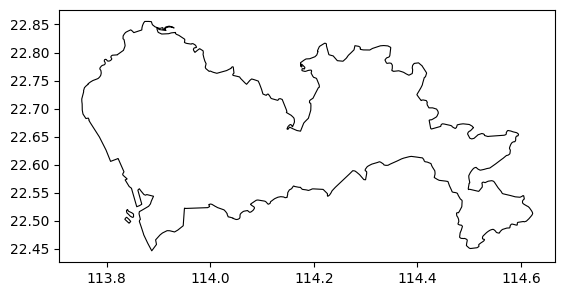

In [2]:
# 导入深圳地图
# 深圳shape
file_name ="../../autodl-fs/shenzhen_polygon/Shenzhen_polygon.shp"
sz_poly = gpd.read_file(file_name)

sz_poly.plot(fc='white',ec='black',linewidth=.8)

In [3]:
# 导入网格数据
grid_path = '../../autodl-fs/ss_city_grid_by_cover.csv'
ss_grid_data = pd.read_csv(grid_path)

# 将ss_grid_date转化为geoDataframe对象，其中geometry为wkt格式
ss_grid_data['wkt'] = ss_grid_data['wkt'].apply(wkt.loads)
ss_grid_data = gpd.GeoDataFrame(ss_grid_data,geometry=ss_grid_data.wkt, crs = 'EPSG:4326')
ss_grid_data.head()

,fnid,chess_x,chess_y,wkt,geometry
0,413,56,1,"MULTIPOLYGON (((113.88581849 22.44961596, 113....","MULTIPOLYGON (((113.88582 22.44962, 113.88826 ..."
1,665,308,1,"MULTIPOLYGON (((114.50078319 22.44961596, 114....","MULTIPOLYGON (((114.50078 22.44962, 114.50322 ..."
2,666,309,1,"MULTIPOLYGON (((114.50322353 22.44961596, 114....","MULTIPOLYGON (((114.50322 22.44962, 114.50566 ..."
3,667,310,1,"MULTIPOLYGON (((114.50566387 22.44961596, 114....","MULTIPOLYGON (((114.50566 22.44962, 114.50810 ..."
4,668,311,1,"MULTIPOLYGON (((114.5081042 22.44961596, 114.5...","MULTIPOLYGON (((114.50810 22.44962, 114.51054 ..."


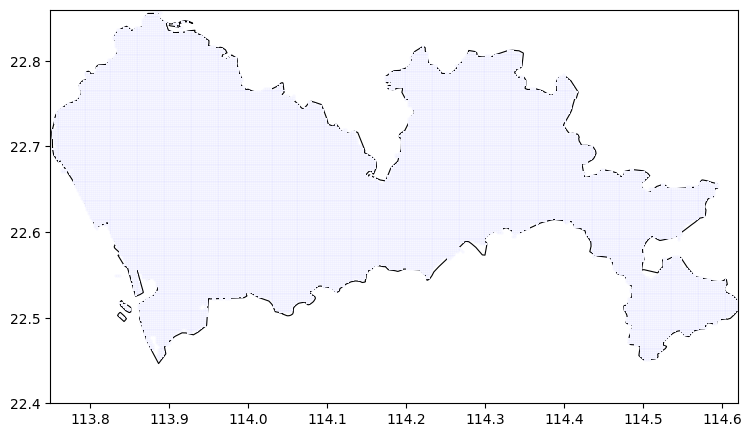

In [9]:
fig = plt.figure(1,(8,8),dpi = 100)
ax = plt.subplot(111)
plt.sca(ax)
fig.tight_layout(rect = (0.05,0.1,1,0.9))

bounds = [113.75, 22.4, 114.62, 22.86]

sz_poly.plot(ax=ax,fc='white',ec='black',linewidth=.8)
ss_grid_data.plot(ax=ax,fc='white',ec='blue',linewidth=.02)

plt.xlim(bounds[0],bounds[2])
plt.ylim(bounds[1],bounds[3])
plt.show()

### 将活动点划分时期

将调整时刻设为t=0
* T1-前稳定：(-limit, -5)周
* T2-过渡：[-5, 0)周
* T3-适应：[0,+8)周
* T4-后稳定：[+8, +limit)周

In [9]:
# 计算每个用户的时期划分点
def calculate_period_points(group):
    first_row = group.iloc[0]
    home_time = first_row['home_time']
    work_time = first_row['work_time']
    
    if home_time >= 0 and work_time >= 0:
        t_min = min(home_time, work_time)
        t_max = max(home_time, work_time)
        period_points = {
            'period0_end': t_min - 4,
            'period1_end': t_max,
            'period2_end': t_max + 8
        }
    elif home_time >= 0:
        period_points = {
            'period0_end': home_time - 4,
            'period1_end': home_time,
            'period2_end': home_time + 8
        }
    elif work_time >= 0:
        period_points = {
            'period0_end': work_time - 4,
            'period1_end': work_time,
            'period2_end': work_time + 8
        }
    else:
        period_points = {
            'period0_end': np.nan,
            'period1_end': np.nan, 
            'period2_end': np.nan
        }
    
    group['period'] = 0
    group.loc[(group['t'] >= period_points['period0_end']) & (group['t'] < period_points['period1_end']), 'period'] = 1
    group.loc[(group['t'] >= period_points['period1_end']) & (group['t'] < period_points['period2_end']), 'period'] = 2
    group.loc[group['t'] >= period_points['period2_end'], 'period'] = 3
    
    return group

In [10]:
def vectorized_period_assignment(full_data, relocate_info_filter):
    # 预计算每个pid的时间节点
    period_params = relocate_info_filter[['pid', 'home_time', 'work_time']].drop_duplicates()
    
    # 计算三类情况的时间节点（向量化操作）
    mask_both = (period_params['home_time'] >= 0) & (period_params['work_time'] >= 0)
    mask_home = (period_params['home_time'] >= 0) & (period_params['work_time'] < 0)
    mask_work = (period_params['home_time'] < 0) & (period_params['work_time'] >= 0)

    period_params['period0_end'] = np.select(
        [mask_both, mask_home, mask_work],
        [
            np.minimum(period_params['home_time'], period_params['work_time']) - 4,
            period_params['home_time'] - 4,
            period_params['work_time'] - 4
        ],
        default=np.nan
    )
    
    period_params['period1_end'] = np.select(
        [mask_both, mask_home, mask_work],
        [
            np.maximum(period_params['home_time'], period_params['work_time']),
            period_params['home_time'],
            period_params['work_time']
        ],
        default=np.nan
    )
    
    period_params['period2_end'] = np.select(
        [mask_both, mask_home, mask_work],
        [
            np.maximum(period_params['home_time'], period_params['work_time']) + 8,
            period_params['home_time'] + 8,
            period_params['work_time'] + 8
        ],
        default=np.nan
    )

    # 合并到主数据
    full_data = full_data.merge(
        period_params[['pid', 'period0_end', 'period1_end', 'period2_end']], 
        on='pid', 
        how='left'
    )

    # 向量化时期分配
    conditions = [
        full_data['t'] < full_data['period0_end'],  # period 0
        (full_data['t'] >= full_data['period0_end']) & (full_data['t'] < full_data['period1_end']),  # period 1
        (full_data['t'] >= full_data['period1_end']) & (full_data['t'] < full_data['period2_end']),  # period 2
        full_data['t'] >= full_data['period2_end']  # period 3
    ]
    
    full_data['period'] = np.select(conditions, [0, 1, 2, 3], default=0)
    
    # 清理中间列
    full_data.drop(columns=['period0_end', 'period1_end', 'period2_end'], inplace=True)
    
    return full_data

In [11]:
# 添加时期列
# full_data_period = full_data.groupby('pid').apply(calculate_period_points)
full_data_period = vectorized_period_assignment(full_data, relocate_info_filter)
full_data_period.head()

,pid,fnid,year,week_number,lon,lat,duration,frequency,t,home_time,work_time,period
0,270.0,35084,2023,9,113.990100,22.664861,285252,5,0,42.0,-1.0,0
1,270.0,16184,2023,10,114.040146,22.548752,5816,1,1,42.0,-1.0,0
2,270.0,35084,2023,10,113.990100,22.664861,299368,8,1,42.0,-1.0,0
3,270.0,35444,2023,10,113.997586,22.666864,20705,2,1,42.0,-1.0,0
4,270.0,35084,2023,11,113.990100,22.664861,266073,6,2,42.0,-1.0,0


In [12]:
# 导出一下
full_data_period.to_csv('../data/stay_data_23_24_timeinfo.csv', index=False)

In [4]:
full_data_period = pd.read_csv('../data/stay_data_23_24_timeinfo.csv')

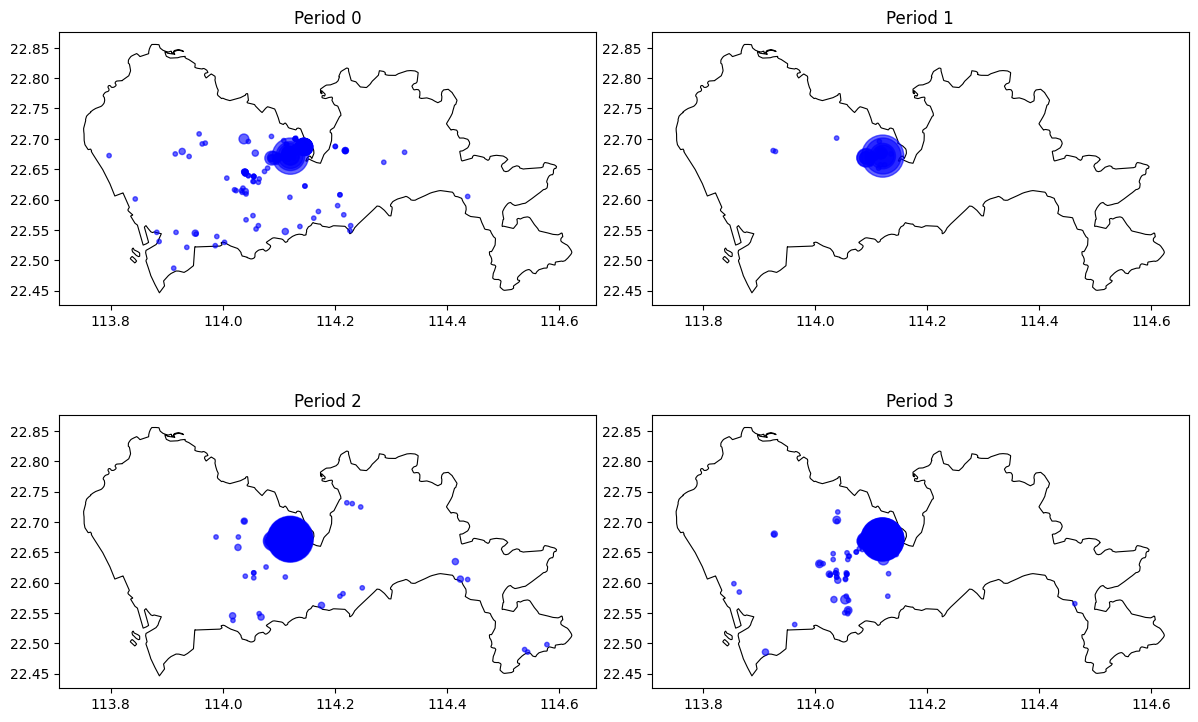

In [46]:
# 随机抽取一个pid的所有数据，并按照year, week_number排序
pid = full_data_period['pid'].sample(1).values[0]
sample_data = full_data_period[full_data_period['pid'] == pid].sort_values(['year', 'week_number']).reset_index(drop=True)

# 将sample_data转为gpd
sample_data = gpd.GeoDataFrame(sample_data, geometry=gpd.points_from_xy(sample_data.lon, sample_data.lat), 
                               crs = 'EPSG:4326')

# 可视化驻留点

# 每两周绘制一张图
# 创建2x2的子图布局
# 创建2x2的子图布局
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

# 遍历4个子图位置
for i in range(4):
    # 获取当前两周的数据
    
    # 绘制第一周数据
    plot_data = sample_data[sample_data['period'] == i]
    sz_poly.plot(fc='white', ec='black', linewidth=.8, ax=axes[i])
    axes[i].scatter(plot_data.geometry.x,
                     plot_data.geometry.y, 
                     s=plot_data['frequency']*10,
                     alpha=0.6,
                     c='blue')
    
    # 设置标题和图例
    axes[i].set_title(f'Period {i}')

plt.tight_layout()
plt.show()



## 1. Spatial-Temporal Kernal
* 使用一个sample的数据可视化核密度

1.投影到适合距离计算的坐标系，例如EPSG:3857

In [47]:
gdf_sample= sample_data.to_crs(epsg=3857)

# # 提取投影后的x, y坐标
gdf_sample['x'] = gdf_sample.geometry.x
gdf_sample['y'] = gdf_sample.geometry.y

2. 构造 3D 数据（空间 + 时间）

In [48]:
# 选择权重（这里使用 frequency，也可根据需要更换为 duration）
weights = gdf_sample['frequency'].values

# 构造原始数据矩阵（x, y, t）
data = gdf_sample[['x', 'y']].values

3. 定义带宽并对数据进行缩放

In [49]:
# 定义空间带宽（单位为米），需根据实际情况调参
spatial_bandwidth = 1000   # 例如：1000米

# 对每个维度进行缩放
data_scaled = np.column_stack((
    gdf_sample['x'] / spatial_bandwidth,
    gdf_sample['y'] / spatial_bandwidth,
))


4. 使用 KernelDensity 进行核密度估计

In [ ]:
# 注意：数据已按各自带宽缩放，因此设定bandwidth=1
# kde = KernelDensity(bandwidth=1, kernel='gaussian')
# kde.fit(data_scaled, sample_weight=weights)

5. 匹配到网格

In [15]:
# 将网格数据投影到与gdf_sample相同的坐标系（EPSG:3857）
ss_grid_data = ss_grid_data.to_crs(epsg=3857)

# 计算每个网格的质心
ss_grid_data['centroid'] = ss_grid_data.geometry.centroid
ss_grid_data['x'] = ss_grid_data['centroid'].x
ss_grid_data['y'] = ss_grid_data['centroid'].y

In [26]:
# # 在网格中心处评估核密度

# # 选择一个时间评价值 t_eval（例如，使用样本时间的中位数）
# t_eval = np.median(gdf_sample['time'])

# # 构造网格评价点，并按相同带宽缩放
# eval_points = np.column_stack((
#     ss_grid_data['x'] / spatial_bandwidth,
#     ss_grid_data['y'] / spatial_bandwidth,
#     np.full(len(ss_grid_data), t_eval / temporal_bandwidth)
# ))

# # 计算每个评价点的对数密度，再取指数得到密度值
# log_density = kde.score_samples(eval_points)
# density = np.exp(log_density)

# # 将密度赋值给网格数据
# ss_grid_data['density'] = density

In [50]:
density_results = []  # 用于保存每个时间切片的核密度结果

for period in range(4):
    # 筛选当前时间窗口的数据点
    mask = (gdf_sample['period'] == period)
    current_data = data_scaled[mask]
    current_weights = weights[mask] if weights is not None else None
    
    # 使用当前时间窗口的数据重新拟合KDE
    kde_t = KernelDensity(bandwidth=1)
    kde_t.fit(current_data, sample_weight=current_weights)
    
    # 构造网格评价点：每个网格中心点的(x, y)及固定时间 t_eval
    eval_points = np.column_stack((
        ss_grid_data['x'] / spatial_bandwidth,
        ss_grid_data['y'] / spatial_bandwidth,
    ))
    
    # 计算核密度（score_samples 返回对数密度）
    log_density = kde_t.score_samples(eval_points)
    density = np.exp(log_density)
    
    # 保存当前时间切片的结果
    density_results.append({
         'period': period,
         'density': density
    })

In [18]:
density_results

[{'t_eval': 0,
  'density': array([1.35783786e-072, 0.00000000e+000, 0.00000000e+000, ...,
         3.72630984e-284, 6.16662400e-282, 5.52200998e-290]),
  'year': 2023,
  'week': 9},
 {'t_eval': 2,
  'density': array([1.24559848e-060, 9.91577713e-242, 7.95233707e-244, ...,
         2.40014866e-180, 1.90908493e-178, 5.06117958e-185]),
  'year': 2023,
  'week': 11},
 {'t_eval': 4,
  'density': array([1.15168319e-072, 8.84082893e-225, 5.62945652e-228, ...,
         7.13683950e-281, 1.18218616e-278, 1.15591146e-286]),
  'year': 2023,
  'week': 13},
 {'t_eval': 6,
  'density': array([2.40069320e-085, 5.45814850e-177, 1.20808692e-179, ...,
         3.97101861e-285, 6.60835941e-283, 5.77094769e-291]),
  'year': 2023,
  'week': 15}]

6. 可视化结果

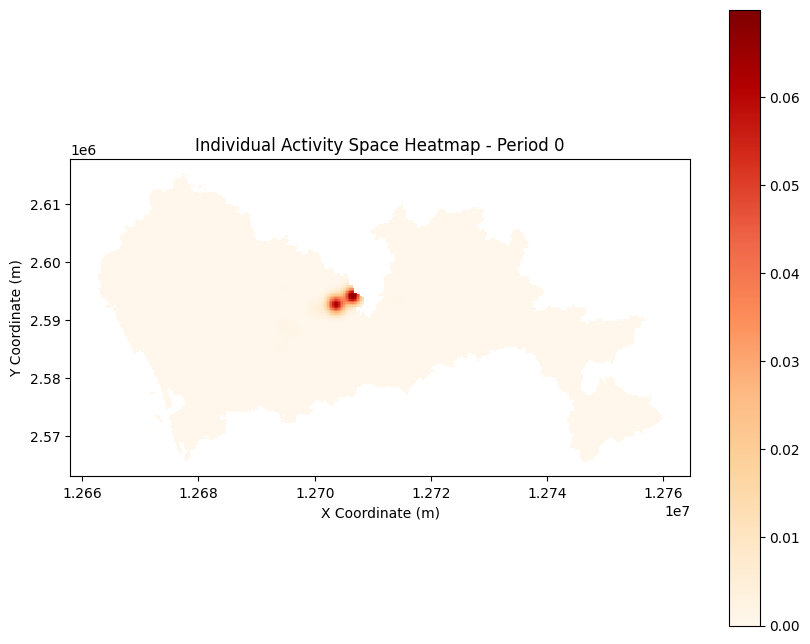

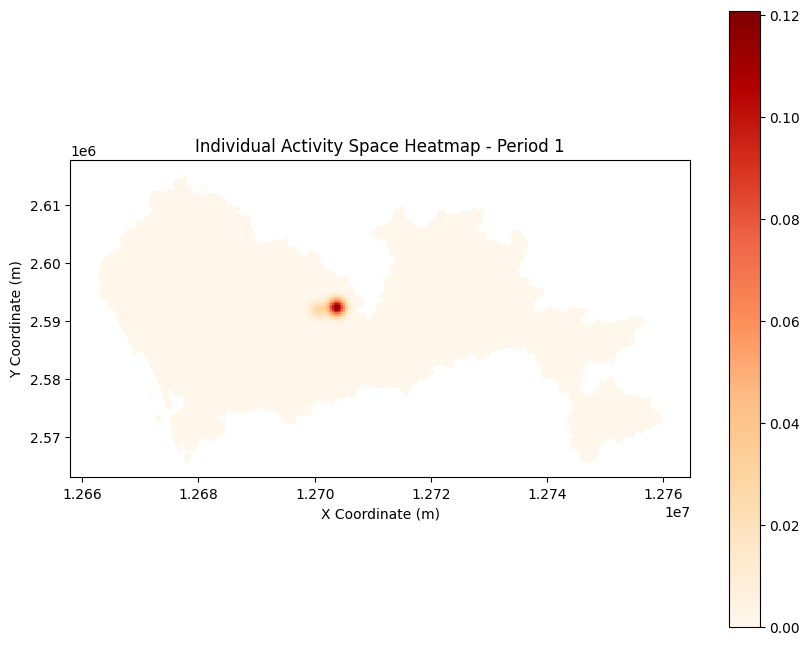

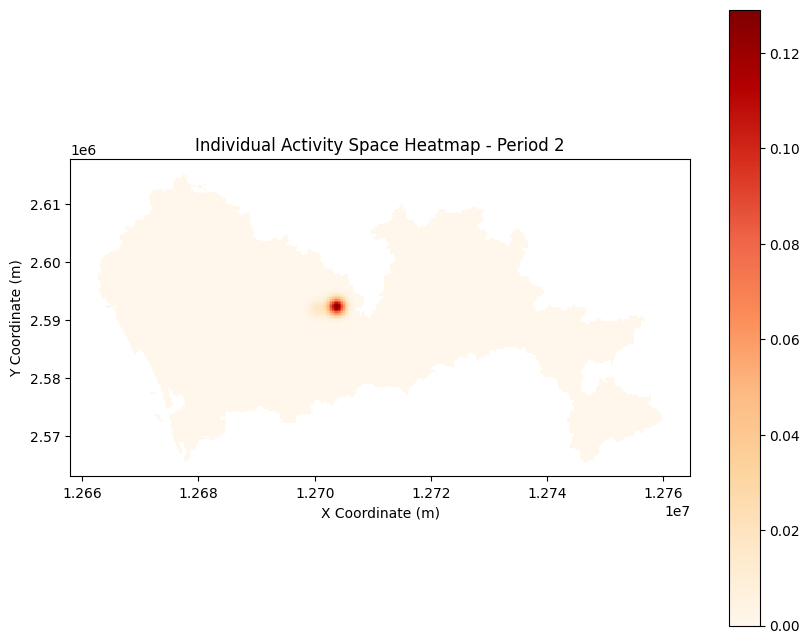

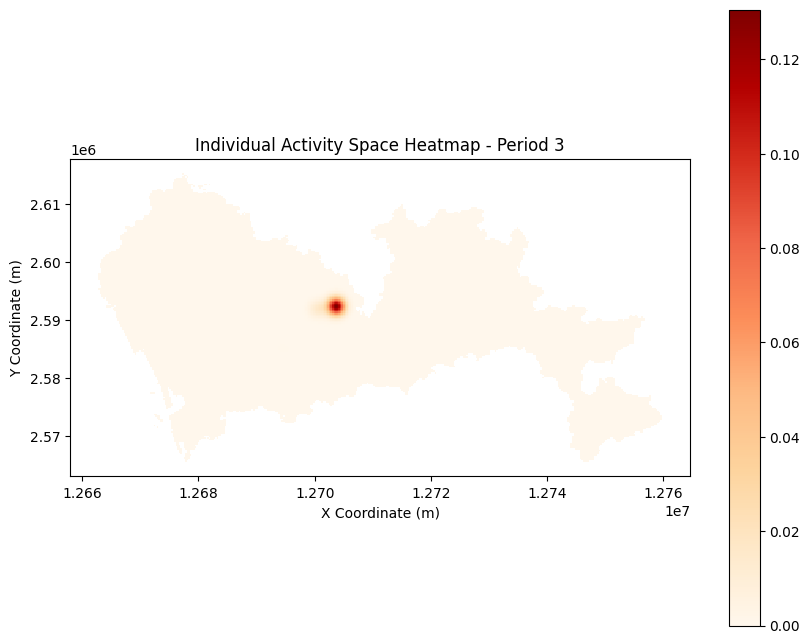

In [51]:
# 这里逐个时间切片生成热力图
for result in density_results:
    
    ss_grid_data['density'] = result['density']
    
    fig, ax = plt.subplots(figsize=(10, 8))
    ss_grid_data.plot(column='density', ax=ax, legend=True,
                      cmap='OrRd')
    ax.set_title(f"Individual Activity Space Heatmap - Period {result['period']}")
    ax.set_xlabel("X Coordinate (m)")
    ax.set_ylabel("Y Coordinate (m)")
    plt.show()

## 2. Activity Space Features

1. 使用核密度法计算活动面积
2. 使用空间聚类判定活动空间中心性（分散程度）

### 2.1 基于核密度计算活动空间面积

In [5]:
def compute_activity_area(ss_grid, density, thershod_rate = 0.3):
    """
    计算活动空间的密度加权覆盖面积
    输入：
        ss_grid：包含网格质心和当前时间窗核密度的 GeoDataFrame
        density：当前时间窗的核密度值
        thershod_rate：密度阈值比例，默认为0.5
    输出：
        high_density_points：密度高于阈值的活动点
        coverage_area：计算的覆盖面积（加权的网格面积之和）
    """
    
    # 将密度值赋给网格
    ss_grid['density'] = density

    # 使用阈值提取高密度区域（阈值：最大密度的50%）
    threshold = thershod_rate * density.max()
    high_density_points = ss_grid[ss_grid['density'] >= threshold]

    # 计算密度加权的网格面积
    # 假设网格是正方形或矩形，面积通过geometry计算
    high_density_points['area'] = high_density_points.geometry.area  # 计算每个网格的面积
    # 计算密度占比加权的活动空间面积
    min_density = high_density_points['density'].min()
    max_density = high_density_points['density'].max()
    high_density_points['normalized_weight'] = (high_density_points['density'] - min_density) / (max_density - min_density)
    
    # 计算加权面积
    high_density_points['weighted_area'] = high_density_points['normalized_weight'] * high_density_points['area']
    
    # sum_den = high_density_points['density'].sum()
    # high_density_points['weighted_area'] = (high_density_points['density']/sum_den) * high_density_points['area']  # 密度加权的面积

    # 计算总的密度加权覆盖面积
    # coverage_area = high_density_points['weighted_area'].sum()
    coverage_area = high_density_points['weighted_area'].sum()

    # ##############使用dbscan聚类，一步到位#################
    # 获取高密度点的坐标，进行聚类
    # coords = np.array([high_density_points.x / spatial_bandwidth, high_density_points.y / spatial_bandwidth]).T
    coords = np.array([high_density_points.chess_x, high_density_points.chess_y / spatial_bandwidth]).T
    dbscan = DBSCAN(eps=1, min_samples=3)
    high_density_points['cluster'] = dbscan.fit_predict(coords)

    # 计算组团数量（排除噪声点-1）
    cluster_count = len(np.unique(high_density_points['cluster'])) - (1 if -1 in high_density_points['cluster'].values else 0)


    return high_density_points, coverage_area / (1000**2), cluster_count  # 转换为平方公里

In [6]:
def compute_activity_area_optimized(ss_grid, density, threshold_rate=0.5, precomputed_area=None):
    """
    优化后的覆盖面积计算函数
    
    参数：
        ss_grid: GeoDataFrame，需包含预计算的面积列
        density: 核密度值数组
        threshold_rate: 阈值比例
        precomputed_area: 预计算的网格面积数组（可选）
    
    返回：
        coverage_area: 覆盖面积（平方公里）
    """
    # 输入验证
    if len(density) != len(ss_grid):
        raise ValueError("Density array length must match ss_grid row count")
    if not (0 <= threshold_rate <= 1):
        raise ValueError("Threshold rate must be between 0 and 1")

    # 预计算面积（如果未提供）
    area = precomputed_area if precomputed_area is not None else ss_grid.geometry.area.values

    # 向量化计算
    max_density = np.nanmax(density)  # 处理可能的NaN值
    threshold = threshold_rate * max_density
    mask = density >= threshold
    
    # 快速加权求和
    valid_density = density[mask]
    valid_area = area[mask]
    valid_grid = ss_grid[mask].copy()
    
    max_den, min_den = np.max(valid_density), np.min(valid_density)
    # 计算密度加权面积
    weighted_sum = np.dot((valid_density-min_den)/(max_den-min_den), valid_area)

    # #####DBScan聚类##########
    coords = np.array([valid_grid.chess_x, valid_grid.chess_y]).T
    dbscan = DBSCAN(**dbscan_params)
    valid_grid.loc[:, 'cluster'] = dbscan.fit_predict(coords)

    # 计算组团数量（排除噪声点-1）
    cluster_count = len(np.unique(valid_grid['cluster'])) - (1 if -1 in valid_grid['cluster'].values else 0)
    
    return weighted_sum / (1000**2), cluster_count  # 转换为平方公里


#### 空间数据预处理

In [7]:
spatial_bandwidth = 1000

# 在full_data_period采样1000个个体进行下一步计算
# 随机采样1000个不同的个体
n_samples = 1000
sampled_pids = np.random.choice(full_data_period['pid'].unique(), size=n_samples, replace=False)
full_data_period = full_data_period[full_data_period['pid'].isin(sampled_pids)]

# 生成gpd数据
full_data_gpd = gpd.GeoDataFrame(full_data_period, geometry=gpd.points_from_xy(full_data_period.lon, full_data_period.lat), 
                               crs = 'EPSG:4326')

# 预转换坐标系
full_data_gpd = full_data_gpd.to_crs(epsg=3857)
full_data_gpd['x'] = full_data_gpd.geometry.x
full_data_gpd['y'] = full_data_gpd.geometry.y

# 预计算归一化坐标
full_data_gpd['x_scaled'] = full_data_gpd['x'] / spatial_bandwidth
full_data_gpd['y_scaled'] = full_data_gpd['y'] / spatial_bandwidth

In [8]:
# 预生成网格评估点（全局复用）
ss_grid_scaled = ss_grid_data.copy()
# 将网格数据投影到与gdf_sample相同的坐标系（EPSG:3857）
ss_grid_scaled = ss_grid_scaled.to_crs(epsg=3857)

# 计算每个网格的质心
ss_grid_scaled['centroid'] = ss_grid_scaled.geometry.centroid
ss_grid_scaled['x'] = ss_grid_scaled['centroid'].x
ss_grid_scaled['y'] = ss_grid_scaled['centroid'].y
ss_grid_scaled['x'] /= spatial_bandwidth
ss_grid_scaled['y'] /= spatial_bandwidth
eval_points = ss_grid_scaled[['x', 'y']].values

In [9]:
ss_grid_scaled['precomputed_area'] = ss_grid_scaled.geometry.area
precomputed_area = ss_grid_scaled.geometry.area.values

#### 实行并行计算

In [10]:
activity_space_areas_dict = {}

# 预先获取所有唯一pid-period组合
all_pids = full_data_gpd['pid'].unique()
total_tasks = len(all_pids)

# 设置kde参数
kde_params = {
    'bandwidth': 1,
    'algorithm': 'kd_tree',
    'metric': 'euclidean',
    'leaf_size': 40,  # 根据数据规模调整，通常30-50最佳
    'kernel': 'gaussian'
}

# 设置dbscan参数
dbscan_params = {
    'eps': 1,
    'min_samples': 3
}

In [11]:
def process_single_pid(pid, pid_data):
    """处理单个用户的函数"""
    pid_areas = []
    cluster_counts = []
    for period in range(4):
        period_data = pid_data[pid_data['period'] == period]
        if len(period_data) < 2:
            pid_areas.append(0.0)
            continue
            
        data_scaled = period_data[['x_scaled', 'y_scaled']].values
        weights = period_data['frequency'].values
        
        kde = KernelDensity(**kde_params)
        kde.fit(data_scaled, sample_weight=weights)
        
        log_density = kde.score_samples(eval_points)
        density = np.exp(log_density)
        
        coverage_area, cluster_count = compute_activity_area_optimized(
            ss_grid_scaled, density, 
            precomputed_area=precomputed_area
        )
        pid_areas.append(coverage_area)
        cluster_counts.append(cluster_count)

    return (pid, pid_areas, cluster_counts)

In [12]:
def parallel_processing(data, n_jobs=-1, chunk_size=100):
    """
    并行处理主函数
    :param n_jobs: 并行进程数，-1表示使用所有核心
    :param chunk_size: 任务分块大小（每个子进程处理chunk_size个用户）
    """
    # 预先分组并转换为列表
    groups = [(pid, group) for pid, group in data.groupby('pid')]
    
    # 创建并行任务迭代器
    tasks = (delayed(process_single_pid)(pid, group) 
             for pid, group in groups)
    
    # 带进度条的并行计算
    results = Parallel(n_jobs=n_jobs, batch_size=chunk_size)(
        tqdm(tasks, total=len(groups), desc='Processing')
    )
    
    # 转换为字典
    return {pid: (areas, cluster_count) for pid, areas, cluster_count in results}

In [13]:
## version 1: 并行代码 ####################################
activity_space_areas_dict = parallel_processing(full_data_gpd)

# # 保存结果
with open('activity_space_areas_dict_sample1000.pkl', 'wb') as f:
    pickle.dump(activity_space_areas_dict, f)

Processing:   0%|          | 0/1000 [00:00<?, ?it/s]

In [19]:
len(activity_space_areas_dict.keys())

1000

In [29]:
## version 2 ############################################
# 添加进度条
with tqdm(total=total_tasks, desc='Processing Individuals') as pbar:
    for pid in all_pids:
        pid_areas = []
        cluster_counts = []
        
        # 向量化提取该用户所有时期数据
        pid_mask = full_data_gpd['pid'] == pid
        pid_data = full_data_gpd[pid_mask]
        
        # 按时期处理
        for period in range(4):
            period_mask = pid_data['period'] == period
            period_data = pid_data[period_mask]
            
            # 跳过无效数据（数据点<2时无法生成有效KDE）
            if len(period_data) < 2:
                pid_areas.append(0.0)
                continue
                
            # 向量化数据准备
            data_scaled = period_data[['x_scaled', 'y_scaled']].values
            weights = period_data['frequency'].values
            
            # 使用预配置模型
            kde = KernelDensity(**kde_params)
            kde.fit(data_scaled, sample_weight=weights)
            
            # 批量计算密度
            log_density = kde.score_samples(eval_points)
            density = np.exp(log_density)
            
            # 快速面积计算
            coverage_area, cluster_count = compute_activity_area_optimized(
                ss_grid_scaled, 
                density,
                precomputed_area=precomputed_area
            )
            pid_areas.append(coverage_area)
            cluster_counts.append(cluster_count)

        
        activity_space_areas_dict[pid] = (pid_areas, cluster_counts)
        pbar.update(1)

Processing Individuals:   0%|          | 0/110261 [00:00<?, ?it/s]

/root/miniconda3/envs/new_causal/lib/python3.8/site-packages/geopandas/geodataframe.py:1538: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super().__setitem__(key, value)
/root/miniconda3/envs/new_causal/lib/python3.8/site-packages/geopandas/geodataframe.py:1538: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super().__setitem__(key, value)
/root/miniconda3/envs/new_causal/lib/python3.8/site-packages/geopandas/geodataframe.py:1538: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice fro

KeyboardInterrupt: 

In [ ]:
## version 3 ############################################
for pid, pid_data in full_data_gpd.groupby('pid'):
    activity_space_areas = []
    
    # 按时期分组处理
    for period, period_data in pid_data.groupby('period'):
        # 向量化提取数据
        data_scaled = period_data[['x_scaled', 'y_scaled']].values
        weights = period_data['frequency'].values
        
        # 优化KDE参数
        kde = KernelDensity(bandwidth=1, algorithm='kd_tree', metric='euclidean')
        kde.fit(data_scaled, sample_weight=weights)
        
        # 批量计算密度
        log_density = kde.score_samples(eval_points)
        density = np.exp(log_density)
        
        # 快速面积计算
        coverage_area = compute_activity_area_optimized(ss_grid_scaled, density, threshold_rate=0.5)
        activity_space_areas.append(coverage_area)
    
    activity_space_areas_dict[pid] = activity_space_areas

#### 个体示例

/root/miniconda3/envs/new_causal/lib/python3.8/site-packages/geopandas/geodataframe.py:1538: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super().__setitem__(key, value)
/root/miniconda3/envs/new_causal/lib/python3.8/site-packages/geopandas/geodataframe.py:1538: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super().__setitem__(key, value)
/root/miniconda3/envs/new_causal/lib/python3.8/site-packages/geopandas/geodataframe.py:1538: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice fro

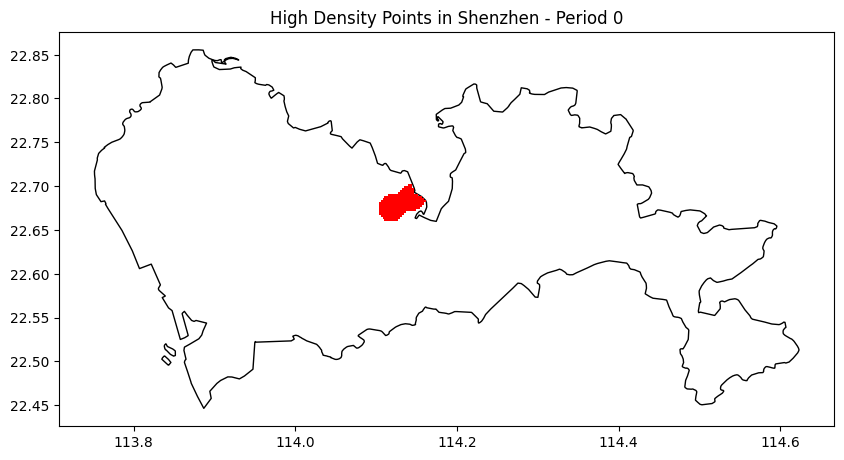

/root/miniconda3/envs/new_causal/lib/python3.8/site-packages/geopandas/geodataframe.py:1538: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super().__setitem__(key, value)
/root/miniconda3/envs/new_causal/lib/python3.8/site-packages/geopandas/geodataframe.py:1538: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super().__setitem__(key, value)
/root/miniconda3/envs/new_causal/lib/python3.8/site-packages/geopandas/geodataframe.py:1538: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice fro

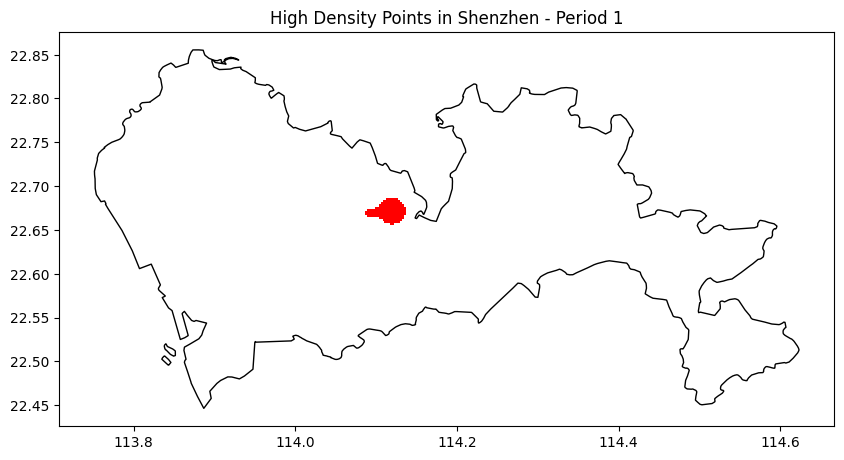

/root/miniconda3/envs/new_causal/lib/python3.8/site-packages/geopandas/geodataframe.py:1538: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super().__setitem__(key, value)
/root/miniconda3/envs/new_causal/lib/python3.8/site-packages/geopandas/geodataframe.py:1538: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super().__setitem__(key, value)
/root/miniconda3/envs/new_causal/lib/python3.8/site-packages/geopandas/geodataframe.py:1538: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice fro

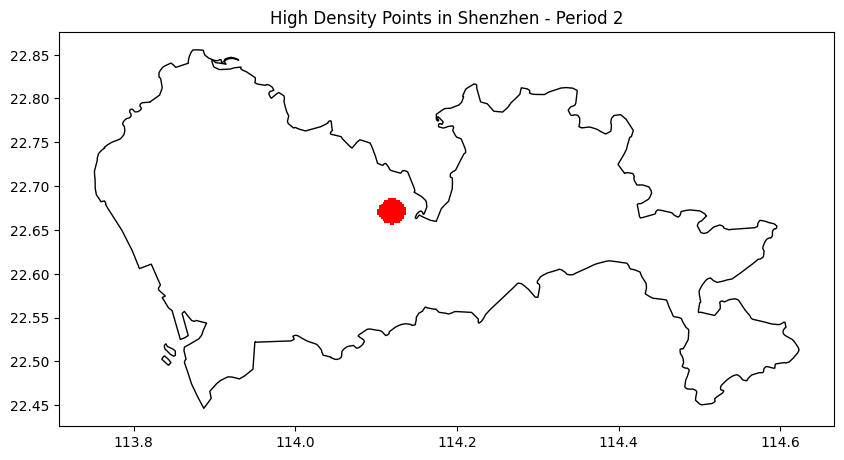

/root/miniconda3/envs/new_causal/lib/python3.8/site-packages/geopandas/geodataframe.py:1538: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super().__setitem__(key, value)
/root/miniconda3/envs/new_causal/lib/python3.8/site-packages/geopandas/geodataframe.py:1538: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super().__setitem__(key, value)
/root/miniconda3/envs/new_causal/lib/python3.8/site-packages/geopandas/geodataframe.py:1538: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice fro

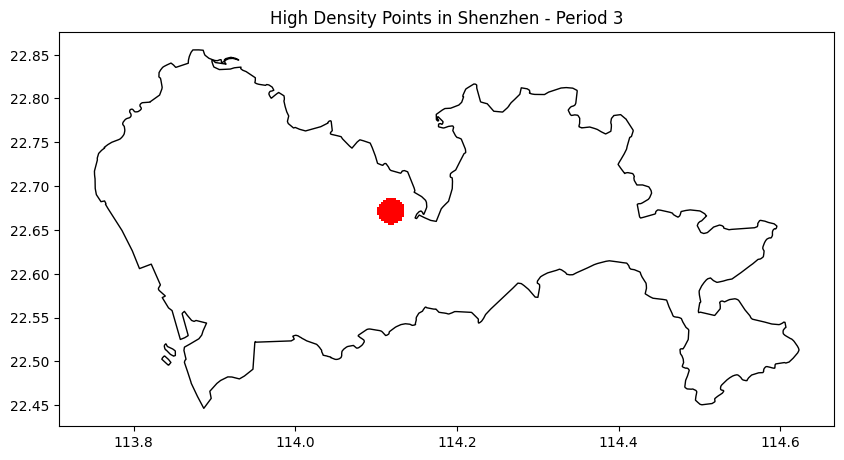

活动空间随时间变化:
   period      area  cluster
0       0  7.611269        1
1       1  4.127228        1
2       2  3.985406        1
3       3  4.015237        1


In [69]:
# 遍历时间切片，计算并保存每个切片下的核密度结果及活动空间特征
density_results = []
activity_space_areas = []

for period in range(4):
    # 筛选当前时间窗口的数据点
    mask = (gdf_sample['period'] == period)
    current_data = data_scaled[mask]
    current_weights = weights[mask] if weights is not None else None
    
    # 使用当前时间窗口的数据重新拟合KDE
    kde_t = KernelDensity(bandwidth=1)
    kde_t.fit(current_data, sample_weight=current_weights)

    # 构造网格评价点：每个网格中心的(x,y)以及固定时间 t_eval（注意缩放）
    eval_points = np.column_stack((
            ss_grid_data['x'] / spatial_bandwidth,
            ss_grid_data['y'] / spatial_bandwidth
        ))
    
    # 计算当前时间切片的核密度
    log_density = kde_t.score_samples(eval_points)
    density = np.exp(log_density)
    
    # 计算当前时间切片的活动空间范围
    high_density_points, coverage_area, cluster_count = compute_activity_area(ss_grid_data.copy(), density, thershod_rate = 0.2)
    
    # 保存活动空间面积结果
    activity_space_areas.append({
        'period': period,
        'area': coverage_area,
        'cluster': cluster_count,
        # 'year': complete_time.loc[t_eval, 'year'],
        # 'week': complete_time.loc[t_eval, 'week_number']
    })

    # 创建一个GeoDataFrame来存储高密度点，并将坐标系转化为经纬度
    high_density_gdf = gpd.GeoDataFrame(high_density_points, geometry='geometry', crs='EPSG:3857')
    high_density_gdf = high_density_gdf.to_crs(epsg=4326)

    # 绘制深圳地图
    fig, ax = plt.subplots(figsize=(10, 10))
    sz_poly.plot(ax=ax, color='white', edgecolor='black')

    # 绘制高密度点
    high_density_gdf.plot(ax=ax, marker='o', color='red', markersize=5)

    plt.title(f'High Density Points in Shenzhen - Period {period}')
    plt.show()

# 将活动空间面积结果转换为DataFrame
areas_df = pd.DataFrame(activity_space_areas)
print("活动空间随时间变化:")
print(areas_df)

In [67]:
high_density_gdf['density'].sum()

9.790329042560671

### 2.2 空间聚类计算活动空间类型
* 单中心？双中心？多中心？
* Hasanzadeh, K. (2019). Exploring centricity of activity spaces: From measurement to the identification of personal and environmental factors. Travel Behaviour and Society, 14, 57-65.

In [ ]:
# 导入居住地信息
anchor_data = pd.read_csv('../../autodl-fs/relocate_information_gpd.csv')

# 导入迁居日期信息
home_week = pd.read_csv('E:/317资料/毕业论文/data/homechange_week.csv')
# wer重命名为pid
home_week = home_week.rename(columns={'wer': 'pid'})

# 根据pid关联anchor_data和home_week，缺失的行补-1
anchor_data = pd.merge(anchor_data, home_week[['pid','date','year','week_number']], on='pid', how='left')

# 将缺失值填充为-1
anchor_data = anchor_data.fillna(-1)

anchor_data.head()

FileNotFoundError: [Errno 2] No such file or directory: 'E:/317资料/毕业论文/data/建成环境数据/relocate_information_gpd.csv'

In [62]:
# 选取样本个体的数据
anchor_data_sample = anchor_data[anchor_data['pid'] == pid]

# 在sample_data根据时间信息匹配home的wkt
# 获取家的记录(anchor=0)
home_records = anchor_data_sample[anchor_data_sample['anchor'] == 0]


# 如果只有一条家的记录
if len(home_records) == 1:
    # 直接将该geometry赋给所有行
    sample_data['home_geometry'] = home_records.iloc[0]['geometry']
else:
    # 有多条记录说明发生迁居
    # 获取迁居时间
    # 获取迁居时间的年份和周数
    move_year = home_records.iloc[0]['year']
    move_week = home_records.iloc[0]['week_number']
    
    # 对sample_data每行判断时间
    def get_home_geometry(row):
        # 直接比较年份和周数
        if row['year'] < move_year or (row['year'] == move_year and row['week_number'] < move_week):
            # 迁居前使用group_id=1的家的geometry
            return home_records[home_records['group_id']==1].iloc[0]['geometry']
        else:
            # 迁居后使用group_id=2的家的geometry
            return home_records[home_records['group_id']==2].iloc[0]['geometry']
            
    sample_data['home_geometry'] = sample_data.apply(get_home_geometry, axis=1)

# 根据home_geometry计算家的中心点
sample_data['home_center'] = sample_data['home_geometry'].apply(lambda x: wkt.loads(x).centroid if x else None)



In [63]:
sample_data.head()

,pid,fnid,year,week_number,lon,lat,duration,frequency,t,geometry,home_geometry,home_center
0,9383832.0,53257,2023,9,113.906937,22.779465,11587,1,0,POINT (113.90694 22.77946),"POLYGON ((113.83213109 22.76871383, 113.834571...",POINT (113.83457143000001 22.767605849999995)
1,9383832.0,52542,2023,9,113.904190,22.775345,2482,1,0,POINT (113.90419 22.77534),"POLYGON ((113.83213109 22.76871383, 113.834571...",POINT (113.83457143000001 22.767605849999995)
2,9383832.0,53966,2023,9,113.894577,22.783585,3287,1,0,POINT (113.89458 22.78358),"POLYGON ((113.83213109 22.76871383, 113.834571...",POINT (113.83457143000001 22.767605849999995)
3,9383832.0,55744,2023,9,113.878098,22.793198,9140,1,0,POINT (113.87810 22.79320),"POLYGON ((113.83213109 22.76871383, 113.834571...",POINT (113.83457143000001 22.767605849999995)
4,9383832.0,51092,2023,9,113.849945,22.765388,12429,4,0,POINT (113.84995 22.76539),"POLYGON ((113.83213109 22.76871383, 113.834571...",POINT (113.83457143000001 22.767605849999995)


In [67]:
# 将家庭点和驻留点合并
# 提取家庭点坐标
# 将Point对象转换为GeoSeries后再转换坐标系
home_geom_series = gpd.GeoSeries([sample_data['home_center'].iloc[0]], crs="EPSG:4326")
home_geom_3857 = home_geom_series.to_crs(epsg=3857).iloc[0]

# 构造家庭点 DataFrame，家庭点时间设为 -1
home_df = pd.DataFrame({
    'x': [home_geom_3857.x],
    'y': [home_geom_3857.y]
})
home_df['geometry'] = home_df.apply(lambda row: Point(row['x'], row['y']), axis=1)
home_df['t'] = -1
home_df['frequency'] = -1

# 对活动点做同样处理
activity_points = gdf_sample.to_crs(epsg=3857)
activity_points['x'] = activity_points.geometry.x
activity_points['y'] = activity_points.geometry.y

all_points = pd.concat([home_df, activity_points[['x','y','geometry','t','frequency']]], ignore_index=True)


c:\ProgramData\Anaconda3\lib\site-packages\pandas\core\dtypes\cast.py:130: ShapelyDeprecationWarning: The array interface is deprecated and will no longer work in Shapely 2.0. Convert the '.coords' to a numpy array instead.
  arr = construct_1d_object_array_from_listlike(values)


In [69]:
# 计算所有点和第一行的点的距离
first_point = all_points.iloc[0][['x','y']].values.reshape(1, -1)
all_points_coords = all_points[['x','y']].values
distances = cdist(first_point, all_points_coords)[0]
all_points['dist'] = distances

,x,y,geometry,t,frequency,dist
0,1.267201e+07,2.603939e+06,POINT (12672006.52625813 2603938.584972595),-1,-1,0.000000
1,1.268006e+07,2.605370e+06,POINT (12680062.185199603 2605370.323977001),0,1,8181.901830
2,1.267976e+07,2.604873e+06,POINT (12679756.437086461 2604872.9115469106),0,1,7806.028695
3,1.267869e+07,2.605868e+06,POINT (12678686.31869047 2605867.7514271354),0,1,6952.791536
4,1.267685e+07,2.607028e+06,POINT (12676851.830011627 2607028.473908282),0,1,5746.684444
...,...,...,...,...,...,...
72,1.268037e+07,2.599071e+06,POINT (12680367.933312746 2599070.8751731226),7,1,9675.108610
73,1.267792e+07,2.603381e+06,POINT (12677921.948407618 2603380.7643421288),7,1,5941.665008
74,1.267201e+07,2.603930e+06,POINT (12672007.551080704 2603929.666383924),7,13,8.977276
75,1.268297e+07,2.574063e+06,POINT (12682966.792274438 2574062.530390742),7,1,31823.043043


In [70]:
all_points[all_points['dist']<3300]

,x,y,geometry,t,frequency,dist
0,1.267201e+07,2.603939e+06,POINT (12672006.52625813 2603938.584972595),-1,-1,0.000000
5,1.267372e+07,2.603671e+06,POINT (12673717.911851933 2603670.893496224),0,4,1732.194959
8,1.267410e+07,2.603215e+06,POINT (12674100.096993359 2603214.9785467214),0,2,2215.094735
9,1.267195e+07,2.603917e+06,POINT (12671951.473805256 2603917.0618803753),0,8,59.110203
11,1.267176e+07,2.606144e+06,POINT (12671756.02812595 2606144.1065019676),0,1,2219.701451
13,1.267334e+07,2.602386e+06,POINT (12673335.726710508 2602386.074575403),0,1,2043.786284
15,1.267104e+07,2.606531e+06,POINT (12671042.615861952 2606531.0113978432),1,1,2765.826824
16,1.267195e+07,2.603917e+06,POINT (12671951.473805256 2603917.0618803753),1,11,59.110203
21,1.267341e+07,2.604790e+06,POINT (12673412.16373879 2604790.010935267),1,1,1643.393713
22,1.267303e+07,2.604210e+06,POINT (12673029.97859737 2604209.7183319605),2,1,1058.757758


In [112]:
# 确定聚类簇数
def find_optimal_clusters(X, max_k=10):
    distortions = []
    # 比较n_samples和max_k
    if X.shape[0] < max_k:
        max_k = X.shape[0]
    for k in range(2, max_k + 1):
        kmeans = KMeans(n_clusters=k, random_state=0)
        kmeans.fit(X)
        distortions.append(kmeans.inertia_)

    # 从 k=2 开始寻找最优值
    # optimal_k = distortions.index(min(distortions[1:])) + 1
    k_range = range(2, max_k + 1)
    knee = KneeLocator(k_range, distortions, curve='convex', direction='decreasing')
    optimal_k = knee.elbow
    return optimal_k, distortions

In [93]:
# def find_optimal_clusters(X, max_k=10):
#     """
#     优化聚类簇数的选择方法，基于多个聚类评估指标：
#     1. 轮廓系数 (Silhouette Score)
#     2. Calinski-Harabasz 指数
#     3. Davies-Bouldin 指数
    
#     参数：
#     - X: 输入的特征矩阵
#     - max_k: 最大簇数（用于计算不同簇数的聚类）

#     返回：
#     - optimal_k: 最优聚类簇数
#     """
#     silhouette_scores = []
#     calinski_scores = []
#     davies_bouldin_scores = []

#     for k in range(2, max_k + 1):
#         kmeans = KMeans(n_clusters=k, random_state=0, n_init=10)
#         kmeans.fit(X)
        
#         # 计算轮廓系数（越大越好）
#         silhouette_avg = silhouette_score(X, kmeans.labels_)
#         silhouette_scores.append(silhouette_avg)
        
#         # 计算 Calinski-Harabasz 指数（越大越好）
#         calinski_score = calinski_harabasz_score(X, kmeans.labels_)
#         calinski_scores.append(calinski_score)
        
#         # 计算 Davies-Bouldin 指数（越小越好）
#         davies_bouldin_score_val = davies_bouldin_score(X, kmeans.labels_)
#         davies_bouldin_scores.append(davies_bouldin_score_val)
    
#     # 根据这些指标选择最优的簇数
#     scores = {
#         'silhouette': silhouette_scores,
#         'calinski': calinski_scores,
#         'davies_bouldin': davies_bouldin_scores
#     }
    
#     # 找到使所有三个指标最优化的簇数
#     optimal_k = np.argmax(np.array(scores['silhouette']) + np.array(scores['calinski']) - np.array(scores['davies_bouldin']))
#     optimal_k += 2  # 因为我们从 k=2 开始评估
    
#     return optimal_k, scores

In [106]:
optimal_clusters, scores = find_optimal_clusters(all_points[['x', 'y']].values)
print(f"Optimal number of clusters (for home and activity points): {optimal_clusters}")

c:\ProgramData\Anaconda3\lib\site-packages\sklearn\cluster\_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
c:\ProgramData\Anaconda3\lib\site-packages\sklearn\cluster\_kmeans.py:1440: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\ProgramData\Anaconda3\lib\site-packages\sklearn\cluster\_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
c:\ProgramData\Anaconda3\lib\site-packages\sklearn\cluster\_kmeans.py:1440: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are

Optimal number of clusters (for home and activity points): 4


c:\ProgramData\Anaconda3\lib\site-packages\sklearn\cluster\_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
c:\ProgramData\Anaconda3\lib\site-packages\sklearn\cluster\_kmeans.py:1440: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\ProgramData\Anaconda3\lib\site-packages\sklearn\cluster\_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
c:\ProgramData\Anaconda3\lib\site-packages\sklearn\cluster\_kmeans.py:1440: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are

In [100]:
scores

[2060337687.3133566,
 495260928.23407775,
 182654950.23520294,
 119341861.9123973,
 62051802.91462079,
 29180901.363481555,
 16092106.995937057,
 10451182.497797275,
 8071322.3209939115,
 5871143.2652474195]

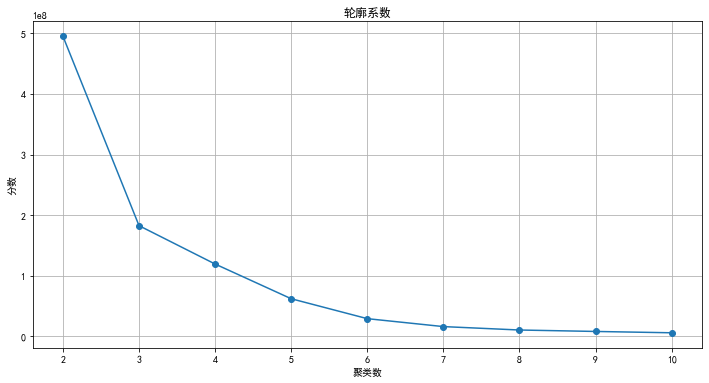

In [ ]:
# 绘制三个指标的变化曲线图
plt.figure(figsize=(12, 6))

# 绘制轮廓系数曲线
plt.plot(range(2, len(scores)+2), scores, marker='o')
plt.title('轮廓系数')
plt.xlabel('聚类数')
plt.ylabel('分数')
plt.grid(True)

In [45]:
all_points.iloc[1:]['t'].nunique()

8

In [134]:
def perform_spatial_clustering(all_points, tw, r1=3300, r2=1000):
    """
    执行空间聚类并计算中心性，返回聚类数和每个点的簇标签。

    参数：
    - all_points: DataFrame，包含活动点的 x, y 坐标，以及其他相关列
    - r1: 第一次聚类的半径，默认为 3300 米
    - r2: 第二次聚类的半径，默认为 1000 米

    返回：
    - centricity: 字符串，表示活动空间的中心性 ('MonoC', 'BiC', 'PolyC')
    - n_m: 整数，表示最终的聚类数 (n + m, 其中 n 为簇的数量，m 为显著簇的数量)
    - final_filtered_points: DataFrame，包含每个点的最终聚类标签和其他信息
    """

    # 确定聚类簇数
    optimal_clusters, _ = find_optimal_clusters(all_points[['x', 'y']].values)
    print(f"Optimal number of clusters (for home and activity points): {optimal_clusters}")
    # optimal_clusters = 5

    # 第一次 K-Means 聚类（条件：r1 < 3.3km）
    kmeans = KMeans(n_clusters=optimal_clusters, random_state=0)
    all_points['cluster'] = kmeans.fit_predict(all_points[['x', 'y']])
    cluster_centers = kmeans.cluster_centers_

    # 计算每个点到聚类中心的距离
    distances_to_centers = cdist(all_points[['x', 'y']], cluster_centers, 'euclidean')

    # 对于每个点，检查是否属于有效聚类，条件是距离小于 r1
    valid_points_mask = np.min(distances_to_centers, axis=1) < r1

    # 过滤掉距离聚类中心超过 r1 的点
    all_points_filtered = all_points[valid_points_mask].copy()

    # 排除包含家庭点的聚类（家庭点在合并后位于第一行，索引 0）
    home_cluster_label = all_points.loc[0, 'cluster']
    home_points = all_points_filtered[all_points_filtered['cluster'] == home_cluster_label]
    # 将home_points的cluster设置为-1
    home_points['cluster'] = -1
    all_points_filtered = all_points_filtered[all_points_filtered['cluster'] != home_cluster_label]

    # 第二次 K-Means 聚类（条件：r2 < 1km）
    optimal_clusters_filtered, _ = find_optimal_clusters(all_points_filtered[['x', 'y']].values)
    print(f"Optimal number of clusters (for home and activity points): {optimal_clusters_filtered}")
    # optimal_clusters_filtered = 5
    
    kmeans_filtered = KMeans(n_clusters=optimal_clusters_filtered, random_state=0)
    all_points_filtered['cluster'] = kmeans_filtered.fit_predict(all_points_filtered[['x', 'y']])

    # 计算每个点到第二次聚类中心的距离
    filtered_distances_to_centers = cdist(all_points_filtered[['x', 'y']], kmeans_filtered.cluster_centers_, 'euclidean')

    # 对于每个点，检查是否属于有效聚类，条件是距离小于 r2
    valid_filtered_points_mask = np.min(filtered_distances_to_centers, axis=1) < r2

    # 过滤掉距离聚类中心超过 r2 的点
    final_filtered_points = all_points_filtered[valid_filtered_points_mask].copy()

    # 计算周数
    period = tw
    
    # 计算每个簇的点数（NOP）和频率之和（Freq）
    cluster_stats = final_filtered_points.groupby('cluster').agg(
        NOP=('cluster', 'size'),  # 计算每个簇的点数
        Freq=('frequency', 'sum')  # 计算每个簇的频率之和
    ).reset_index()

    # 计算显著性（CS = NOP * Freq / period）
    cluster_stats['CS'] = cluster_stats['NOP'] * cluster_stats['Freq'] / period

    # 选择显著性大于等于 2 的簇标签
    valid_clusters = cluster_stats[cluster_stats['CS'] >= 2]['cluster']
    m = len(valid_clusters)

    # 筛选出显著的簇
    valid_filtered_points = final_filtered_points[final_filtered_points['cluster'].isin(valid_clusters.values)]


    # 合并home_cluster和valid_clusters
    final_filtered_points = pd.concat([home_points, valid_filtered_points], ignore_index=True)

    # 判断中心性
    n = 1
    if n+m == 1:
        centricity = 'MonoC'  # 单中心
    elif n+m == 2:
        centricity = 'BiC'    # 双中心
    else:
        centricity = 'PolyC'  # 多中心

    # 返回结果
    n_m = n + m  # 返回聚类数（n + m）
    return centricity, n_m, final_filtered_points

In [135]:
# 设置时间窗口，做动态的空间聚类
tw = 2
# 存储每个时间窗口的聚类结果
clustering_results = []

# 遍历每个时间窗口
for t in range(0, activity_points['t'].max() + 1, tw):

    # 选取该时间段内的家
    home_geom_series = gpd.GeoSeries([sample_data[sample_data['t'] == t]['home_center'].iloc[0]], crs="EPSG:4326")
    home_geom_3857 = home_geom_series.to_crs(epsg=3857).iloc[0]

    # 构造家庭点 DataFrame，家庭点时间设为 -1
    home_df = pd.DataFrame({
        'x': [home_geom_3857.x],
        'y': [home_geom_3857.y]
    })
    home_df['geometry'] = home_df.apply(lambda row: Point(row['x'], row['y']), axis=1)
    home_df['t'] = -1
    home_df['frequency'] = -1

    # 按时间窗口筛选活动点数据
    activity_points_tw = activity_points[
        (activity_points['t'] >= t) & 
        (activity_points['t'] < t + tw)
    ][['x','y','geometry','t','frequency']]
    
    # 合并家庭点和活动点数据
    all_points = pd.concat([home_df, activity_points_tw], ignore_index=True)
    
    # 调用空间聚类函数进行聚类分析
    centricity, n_m, final_filtered_points = perform_spatial_clustering(all_points, tw)
    
    # 存储结果
    clustering_results.append({
        'time_window': (t, t + tw),
        'centricity': centricity,
        'n_m': n_m,
        'final_filtered_points': final_filtered_points
    })



c:\ProgramData\Anaconda3\lib\site-packages\pandas\core\dtypes\cast.py:130: ShapelyDeprecationWarning: The array interface is deprecated and will no longer work in Shapely 2.0. Convert the '.coords' to a numpy array instead.
  arr = construct_1d_object_array_from_listlike(values)
c:\ProgramData\Anaconda3\lib\site-packages\sklearn\cluster\_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
c:\ProgramData\Anaconda3\lib\site-packages\sklearn\cluster\_kmeans.py:1440: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\ProgramData\Anaconda3\lib\site-packages\sklearn\cluster\_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4

Optimal number of clusters (for home and activity points): 4
Optimal number of clusters (for home and activity points): 3


c:\ProgramData\Anaconda3\lib\site-packages\sklearn\cluster\_kmeans.py:1440: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\ProgramData\Anaconda3\lib\site-packages\pandas\core\dtypes\cast.py:130: ShapelyDeprecationWarning: The array interface is deprecated and will no longer work in Shapely 2.0. Convert the '.coords' to a numpy array instead.
  arr = construct_1d_object_array_from_listlike(values)
c:\ProgramData\Anaconda3\lib\site-packages\sklearn\cluster\_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
c:\ProgramData\Anaconda3\lib\site-packages\sklearn\cluster\_kmeans.py:1440: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when ther

Optimal number of clusters (for home and activity points): 4
Optimal number of clusters (for home and activity points): 3

c:\ProgramData\Anaconda3\lib\site-packages\sklearn\cluster\_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
c:\ProgramData\Anaconda3\lib\site-packages\sklearn\cluster\_kmeans.py:1440: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
<ipython-input-134-8618a3fef00d>:39: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  home_points['cluster'] = -1
c:\ProgramData\Anaconda3\lib\site-packages\sklearn\cluster\_kmeans.py:1416: Future

c:\ProgramData\Anaconda3\lib\site-packages\pandas\core\dtypes\cast.py:130: ShapelyDeprecationWarning: The array interface is deprecated and will no longer work in Shapely 2.0. Convert the '.coords' to a numpy array instead.
  arr = construct_1d_object_array_from_listlike(values)
c:\ProgramData\Anaconda3\lib\site-packages\sklearn\cluster\_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
c:\ProgramData\Anaconda3\lib\site-packages\sklearn\cluster\_kmeans.py:1440: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\ProgramData\Anaconda3\lib\site-packages\sklearn\cluster\_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4

Optimal number of clusters (for home and activity points): 4
Optimal number of clusters (for home and activity points): 3


c:\ProgramData\Anaconda3\lib\site-packages\sklearn\cluster\_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
c:\ProgramData\Anaconda3\lib\site-packages\sklearn\cluster\_kmeans.py:1440: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
<ipython-input-134-8618a3fef00d>:39: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  home_points['cluster'] = -1
c:\ProgramData\Anaconda3\lib\site-packages\sklearn\cluster\_kmeans.py:1416: Future

Optimal number of clusters (for home and activity points): 4
Optimal number of clusters (for home and activity points): 3


c:\ProgramData\Anaconda3\lib\site-packages\sklearn\cluster\_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
c:\ProgramData\Anaconda3\lib\site-packages\sklearn\cluster\_kmeans.py:1440: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
<ipython-input-134-8618a3fef00d>:39: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  home_points['cluster'] = -1
c:\ProgramData\Anaconda3\lib\site-packages\sklearn\cluster\_kmeans.py:1416: Future

In [136]:
clustering_results

[{'time_window': (0, 2),
  'centricity': 'MonoC',
  'n_m': 1,
  'final_filtered_points':               x             y                                       geometry  \
  0  1.267201e+07  2.603939e+06    POINT (12672006.52625813 2603938.584972595)   
  1  1.267372e+07  2.603671e+06   POINT (12673717.911851933 2603670.893496224)   
  2  1.267410e+07  2.603215e+06  POINT (12674100.096993359 2603214.9785467214)   
  3  1.267195e+07  2.603917e+06  POINT (12671951.473805256 2603917.0618803753)   
  4  1.267176e+07  2.606144e+06   POINT (12671756.02812595 2606144.1065019676)   
  5  1.267334e+07  2.602386e+06   POINT (12673335.726710508 2602386.074575403)   
  6  1.267104e+07  2.606531e+06  POINT (12671042.615861952 2606531.0113978432)   
  7  1.267195e+07  2.603917e+06  POINT (12671951.473805256 2603917.0618803753)   
  8  1.267341e+07  2.604790e+06    POINT (12673412.16373879 2604790.010935267)   
  
     t  frequency  cluster  
  0 -1         -1       -1  
  1  0          4       -1  
  2

In [125]:
# 获取数据类型信息
print(clustering_results[1]['final_filtered_points'])

              x             y                                       geometry  \
0  1.267201e+07  2.603939e+06    POINT (12672006.52625813 2603938.584972595)   
1  1.267303e+07  2.604210e+06   POINT (12673029.97859737 2604209.7183319605)   
2  1.267341e+07  2.604790e+06    POINT (12673412.16373879 2604790.010935267)   
3  1.267195e+07  2.603917e+06  POINT (12671951.473805256 2603917.0618803753)   
4  1.267303e+07  2.604376e+06    POINT (12673029.97859737 2604375.514133388)   
5  1.267195e+07  2.603917e+06  POINT (12671951.473805256 2603917.0618803753)   
6  1.267288e+07  2.602883e+06  POINT (12672877.104540795 2602883.4119574376)   
7  1.267176e+07  2.606144e+06   POINT (12671756.02812595 2606144.1065019676)   
8  1.269780e+07  2.576918e+06  POINT (12697795.575761767 2576917.5384187833)   

   t  frequency  cluster  
0 -1         -1        1  
1  2          1        1  
2  2          1        1  
3  2         11        1  
4  3          1        1  
5  3         11        1  
6  3      

c:\ProgramData\Anaconda3\lib\site-packages\matplotlib\collections.py:982: RuntimeWarning: invalid value encountered in sqrt
  scale = np.sqrt(self._sizes) * dpi / 72.0 * self._factor
c:\ProgramData\Anaconda3\lib\site-packages\matplotlib\collections.py:982: RuntimeWarning: invalid value encountered in sqrt
  scale = np.sqrt(self._sizes) * dpi / 72.0 * self._factor
c:\ProgramData\Anaconda3\lib\site-packages\matplotlib\collections.py:982: RuntimeWarning: invalid value encountered in sqrt
  scale = np.sqrt(self._sizes) * dpi / 72.0 * self._factor
c:\ProgramData\Anaconda3\lib\site-packages\matplotlib\collections.py:982: RuntimeWarning: invalid value encountered in sqrt
  scale = np.sqrt(self._sizes) * dpi / 72.0 * self._factor
c:\ProgramData\Anaconda3\lib\site-packages\matplotlib\collections.py:982: RuntimeWarning: invalid value encountered in sqrt
  scale = np.sqrt(self._sizes) * dpi / 72.0 * self._factor
c:\ProgramData\Anaconda3\lib\site-packages\matplotlib\collections.py:982: RuntimeWarn

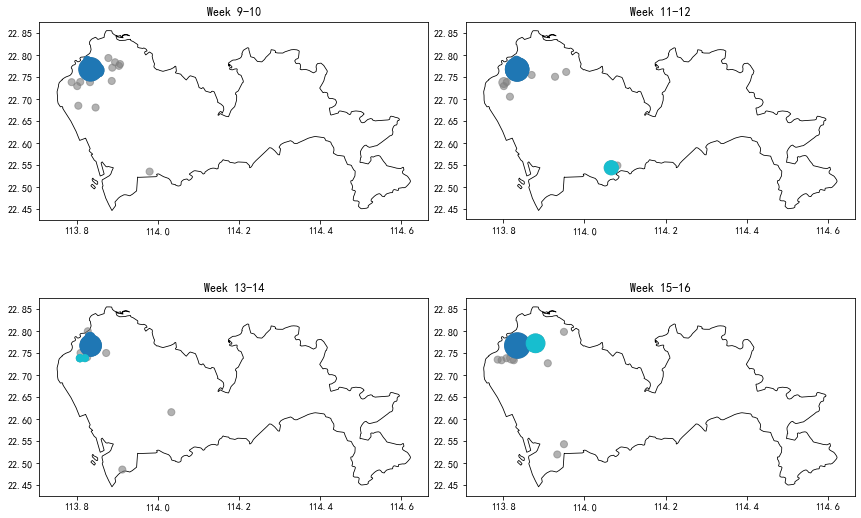

In [142]:
# 每两周绘制一张图
# 创建2x2的子图布局
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

# 遍历4个子图位置
m = 0
for idx, i in enumerate(range(0, len(weeks), 2)):
    # 获取当前两周的数据
    week1 = weeks[i]
    week2 = weeks[i+1]
    
    # 绘制时间段内所有数据
    mask = (sample_data['week_number'] == week1) | (sample_data['week_number'] == week2)
    plot_data = sample_data[mask]
    sz_poly.plot(fc='white', ec='black', linewidth=.8, ax=axes[idx])
    axes[idx].scatter(plot_data.geometry.x,
                     plot_data.geometry.y, 
                     s=plot_data['frequency']*50,
                     alpha=0.6,
                     c='grey')
    
    # 绘制被聚类的点
    cluster_points = clustering_results[m]['final_filtered_points']
    cluster_points = gpd.GeoDataFrame(cluster_points, crs="EPSG:3857")
    cluster_points = cluster_points.to_crs(epsg=4326)
    cluster_points.plot(ax=axes[idx], 
                        markersize=cluster_points['frequency']*50, 
                        column='cluster',
                        cmap='tab10',
                        label='cluster')
    m += 1


    # 设置标题和图例
    axes[idx].set_title(f'Week {week1}-{week2}')

plt.tight_layout()
plt.show()